# Проект: семантический поиск товаров по текстовому запросу

**Ваша роль.** Вы специалист по Data Science. Компания развивает онлайн-каталог товаров, и сейчас руководству кажется, что классический поиск по ключевым словам плохо справляется с реальными запросами. Пользователи пишут названия с ошибками, кириллицей, используют просторечные слова, ищут товары по назначению, а не по функциональности («удобные кроссовки для бега» вместо «мужские спортивные кроссовки с амортизацией»). Команда хочет проверить, поможет ли векторный поиск улучшить качество поисковой системы.

**Задача.** Вам нужно построить MVP системы семантического поиска, сравнить его с лексической baseline-моделью на подготовленной разметке и дать бизнесу обоснованную рекомендацию о том, где новое решение помогает, где ошибается и стоит ли его вообще внедрять.

## Данные

| Файл | Что это | Когда нужен |
|---|---|---|
| wb_products_raw_sample.parquet | Исходный каталог, ~200 тысяч строк, все категории. <br> Вам нужно самостоятельно отобрать рабочее подмножество этих данных | Недели 1–2 |
| wb_products_dedup.parquet | Пул асессоров: множество товаров, по которому делалась разметка | Неделя 2, раздел 4 |
| queries_synthetic_train.parquet | Разметка релевантности, train | Недели 2–3 |
| queries_synthetic_test.parquet | Разметка релевантности, test | **один прогон** в конце недели 3 |

Файлы с разметкой содержат четыре столбца: `query_id`, `query_text`, `item_id`, `relevance`. Шкала в `relevance` от `0` до `3`, где `0` — товар нерелевантен, а `3` — максимально релевантен. Связь с каталогом: `item_id` ↔ `imt_id`.

In [ ]:
# Необходимые файлы
import json
import os
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['OMP_NUM_THREADS'] = '2'
os.environ['MKL_NUM_THREADS'] = '2'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
import random
from pathlib import Path

import boto3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
pd.set_option('display.max_colwidth', 120)
plt.rcParams.update({'figure.figsize': (10, 5), 'font.size': 11})

DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)
RAW_PRODUCTS_PATH = DATA_DIR / 'wb_products_raw_sample.parquet'
ASSESSED_POOL_PATH = DATA_DIR / 'wb_products_dedup.parquet'
TRAIN_QUERIES_PATH = DATA_DIR / 'queries_synthetic_train.parquet'
TEST_QUERIES_PATH = DATA_DIR / 'queries_synthetic_test.parquet'

paths = [RAW_PRODUCTS_PATH, ASSESSED_POOL_PATH, TRAIN_QUERIES_PATH, TEST_QUERIES_PATH]
if any(not path.exists() for path in paths):
    credentials_path = Path(os.getenv('RECSYS_CREDENTIALS', '../.local/credentials.json'))
    credentials = json.loads(credentials_path.read_text(encoding='utf-8'))['student_s3']
    s3 = boto3.client(
        's3', endpoint_url='https://storage.yandexcloud.net',
        aws_access_key_id=credentials['access_key'],
        aws_secret_access_key=credentials['secret_key'],
    )
    for path in paths:
        if not path.exists():
            s3.download_file('s3-ds-source', path.name, str(path))

---

## Неделя 1 — знакомство с данными и EDA

**Цель** — понять, с какими данными работаете, чтобы принять обоснованные решения:

- выбрать категории, с которыми будете работать;
- определить, как будете очищать описания от всего лишнего;
- решить, из каких полей собирать текст товара.

**Главный критерий успеха:** любое ваше решение по данным вы можете подкрепить ссылкой на конкретные результаты анализа.

### 1. Загрузка данных

Загрузите каталог и обе разметки. Изучите их структуру: проанализируйте колонки и типы данных в них, определите, что описывает одна строка.

**Подсказка.** `imt_id` — карточка товара, `nm_id` — конкретный артикул этого товара, то есть его разновидность, отличающаяся цветом, размером или чем-то ещё. Определите, что из этого должен возвращать поиск, — от этого зависит, на каком уровне вы будете строить индекс.

In [ ]:
df_raw = pd.read_parquet(RAW_PRODUCTS_PATH, dtype_backend='pyarrow')
queries_train = pd.read_parquet(TRAIN_QUERIES_PATH)
queries_test = pd.read_parquet(TEST_QUERIES_PATH)

# Ваш код: размеры, колонки, типы, первые строки
display(pd.DataFrame([
    {'dataset': name, 'rows': len(frame), 'columns': frame.shape[1]}
    for name, frame in [('catalog', df_raw), ('train', queries_train), ('test', queries_test)]
]))
display(df_raw.dtypes.to_frame('dtype'))
display(queries_train.dtypes.to_frame('dtype'))
display(df_raw.head(3))
display(queries_train.head(5))

,dataset,rows,columns
0,catalog,200000,9
1,train,11453,4
2,test,4866,4


,dtype
imt_id,int64[pyarrow]
nm_id,int64[pyarrow]
imt_name,string[pyarrow]
subj_name,string[pyarrow]
subj_root_name,string[pyarrow]
nm_colors_names,string[pyarrow]
vendor_code,string[pyarrow]
description,string[pyarrow]
brand_name,string[pyarrow]


,dtype
query_id,str
query_text,str
item_id,int64
relevance,int64


,imt_id,nm_id,imt_name,subj_name,subj_root_name,nm_colors_names,vendor_code,description,brand_name
0,100000,118982,Сумка,Сумки,Аксессуары,бежевый,82992/beige,,Pola
1,1000000,1206857,Шапка,Шапки,Головные уборы,белый,Лаки/белый,,Ваша Шляпка
2,1000000,1206860,Шапка,Шапки,Головные уборы,черный,Лаки/черный,,Ваша Шляпка


,query_id,query_text,item_id,relevance
0,SYN_000001,жилеты на пуговицах,100211,3
1,SYN_000001,жилеты на пуговицах,100433,1
2,SYN_000001,жилеты на пуговицах,1000988,1
3,SYN_000001,жилеты на пуговицах,1016032,1
4,SYN_000001,жилеты на пуговицах,10001023,1


**Проверьте связность данных:** все ли `item_id` из разметки есть в каталоге, нет ли пересечения `query_id` между `train` и `test`.

In [ ]:
# Ваш код
catalog_ids = set(df_raw['imt_id'])
query_id_overlap = set(queries_train['query_id']) & set(queries_test['query_id'])
train_texts = set(queries_train['query_text'].str.strip().str.casefold())
test_texts = set(queries_test['query_text'].str.strip().str.casefold())
text_overlap = train_texts & test_texts
display(pd.DataFrame([
    {
        'dataset': name,
        'queries': frame['query_id'].nunique(),
        'items': frame['item_id'].nunique(),
        'missing_catalog_items': len(set(frame['item_id']) - catalog_ids),
        'duplicate_rows': int(frame.duplicated().sum()),
        'duplicate_query_item_pairs': int(frame.duplicated(['query_id', 'item_id']).sum()),
        'nulls': int(frame.isna().sum().sum()),
        'inconsistent_query_texts': int((frame.groupby('query_id')['query_text'].nunique() > 1).sum()),
    }
    for name, frame in [('train', queries_train), ('test', queries_test)]
]))
print('Пересечение query_id:', len(query_id_overlap))
print('Пересечение текстов запросов:', len(text_overlap))
assert not query_id_overlap and not text_overlap
assert queries_train['relevance'].between(0, 3).all()
assert queries_test['relevance'].between(0, 3).all()
assert queries_train['item_id'].isin(catalog_ids).all()
assert queries_test['item_id'].isin(catalog_ids).all()

,dataset,queries,items,missing_catalog_items,duplicate_rows,duplicate_query_item_pairs,nulls,inconsistent_query_texts
0,train,700,2285,0,0,0,0,0
1,test,300,1672,0,0,0,0,0


Пересечение query_id: 0
Пересечение текстов запросов: 0


### 2. EDA

In [ ]:
# размер каталога и дубликаты
text_columns = [
    'imt_name', 'description', 'nm_colors_names', 'subj_name',
    'subj_root_name', 'brand_name', 'vendor_code',
]
text_fields = df_raw[text_columns].fillna('')
display(pd.Series({
    'rows': len(df_raw),
    'unique_imt_id': df_raw['imt_id'].nunique(),
    'unique_nm_id': df_raw['nm_id'].nunique(),
    'duplicate_rows': int(df_raw.duplicated().sum()),
    'duplicate_imt_id': int(df_raw.duplicated('imt_id').sum()),
    'duplicate_nm_id': int(df_raw.duplicated('nm_id').sum()),
    'root_categories': df_raw['subj_root_name'].nunique(),
    'subject_categories': df_raw['subj_name'].nunique(),
}).to_frame('value'))

,value
rows,200000
unique_imt_id,174427
unique_nm_id,199957
duplicate_rows,0
duplicate_imt_id,25573
duplicate_nm_id,43
root_categories,65
subject_categories,3234


,null_count,empty_or_null_count,empty_or_null_pct
imt_name,0,708,0.35
description,0,57509,28.75
nm_colors_names,0,34226,17.11
subj_name,0,8,0.0
subj_root_name,0,8,0.0
brand_name,0,201,0.1
vendor_code,0,6646,3.32


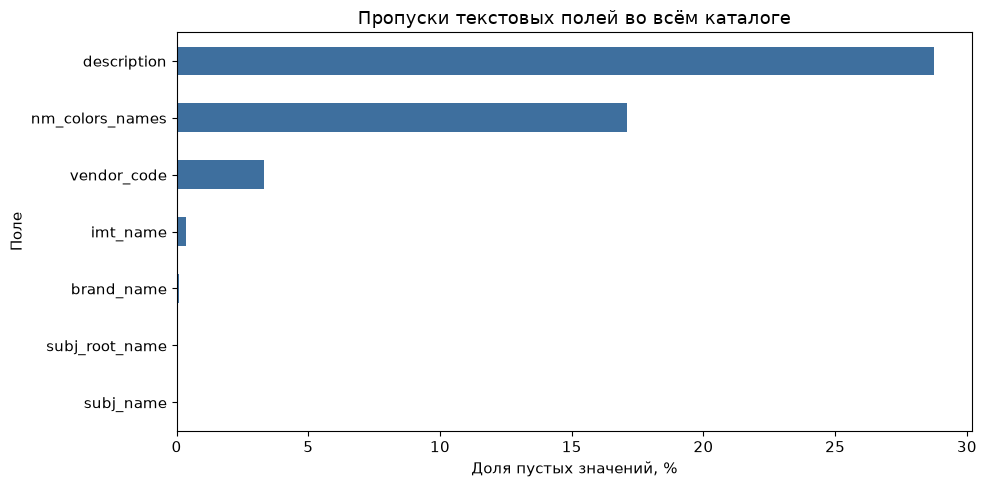

In [ ]:
# пропуски
empty_fields = text_fields.apply(lambda column: column.str.strip().eq(''))
missing = pd.DataFrame({
    'null_count': df_raw[text_columns].isna().sum(),
    'empty_or_null_count': empty_fields.sum(),
    'empty_or_null_pct': empty_fields.mean().mul(100),
})
display(missing.round(2))
missing['empty_or_null_pct'].sort_values().plot.barh(color='#3E6F9E')
plt.title('Пропуски текстовых полей во всём каталоге')
plt.xlabel('Доля пустых значений, %')
plt.ylabel('Поле')
plt.tight_layout()
plt.show()

,rows
subj_root_name,
Одежда,43316
Аксессуары,16446
Дом,15024
Обувь,13187
Красота,9895
Посуда и инвентарь,7799
Смартфоны и аксессуары,6997
Белье,6066
Игрушки,5411


,rows
subj_name,
Платья,6998
Футболки,5465
Сумки,5215
Брюки,3427
Чехлы для телефонов,3169
Постельное белье,2457
Блузки,2342
Костюмы,2317
Автомобильные ароматизаторы,2165


Предметных категорий с 1-2 строками: 757


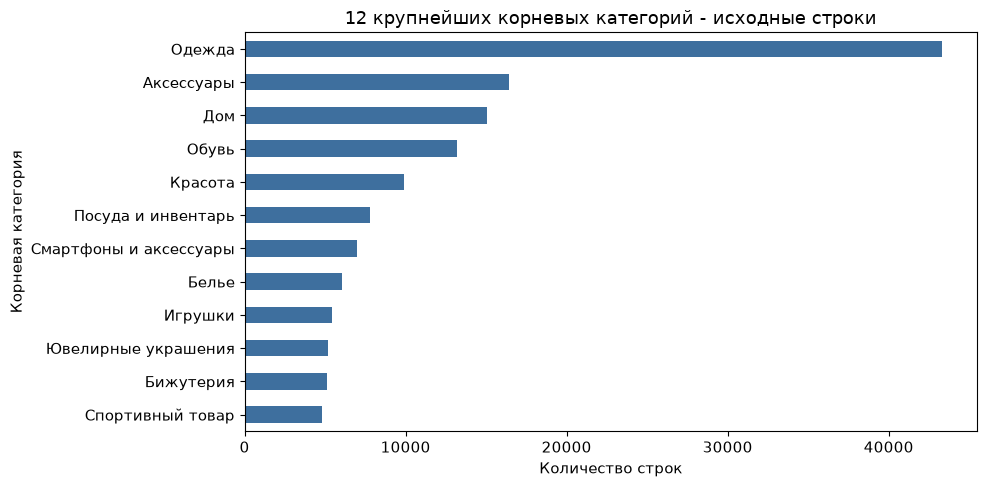

In [ ]:
# категории
root_counts = df_raw['subj_root_name'].fillna('Без категории').value_counts()
subject_counts = df_raw['subj_name'].fillna('Без категории').value_counts()
display(root_counts.head(15).to_frame('rows'))
display(subject_counts.head(15).to_frame('rows'))
print('Предметных категорий с 1-2 строками:', int(subject_counts.le(2).sum()))
root_counts.head(12).sort_values().plot.barh(color='#3E6F9E')
plt.title('12 крупнейших корневых категорий - исходные строки')
plt.xlabel('Количество строк')
plt.ylabel('Корневая категория')
plt.tight_layout()
plt.show()

,name_chars,name_words,description_chars,description_words
count,200000.0,200000.0,200000.0,200000.0
mean,32.9,4.8,372.4,50.4
std,24.0,3.6,474.6,64.6
min,0.0,0.0,0.0,0.0
50%,31.0,4.0,227.0,31.0
90%,65.0,10.0,934.0,125.0
95%,80.0,12.0,1082.0,152.0
99%,97.0,15.0,2067.0,289.0
max,122.0,31.0,5000.0,754.0


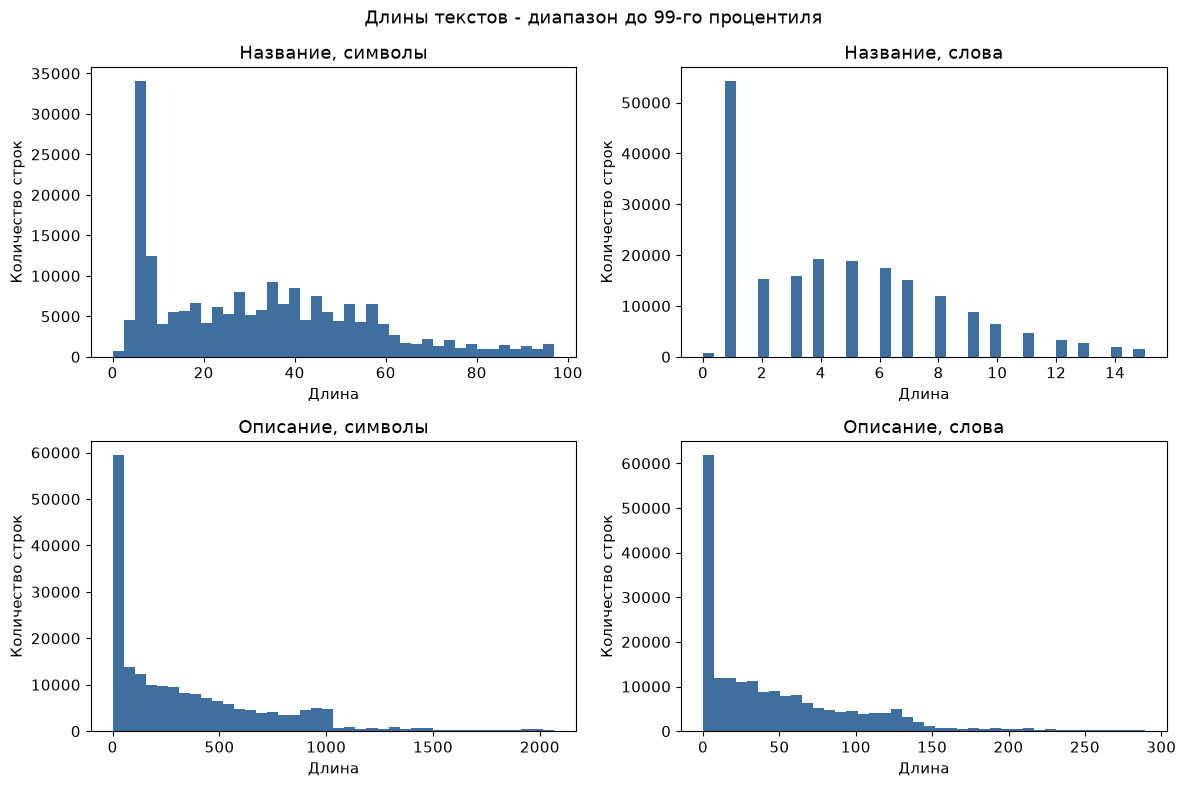

In [ ]:
# длина текстов
lengths = pd.DataFrame({
    'name_chars': text_fields['imt_name'].str.len(),
    'name_words': text_fields['imt_name'].str.count(r'\S+'),
    'description_chars': text_fields['description'].str.len(),
    'description_words': text_fields['description'].str.count(r'\S+'),
})
display(lengths.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(1))
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
labels = ['Название, символы', 'Название, слова', 'Описание, символы', 'Описание, слова']
for ax, column, label in zip(axes.flat, lengths.columns, labels):
    bound = lengths[column].quantile(0.99)
    ax.hist(lengths.loc[lengths[column].le(bound), column], bins=40, color='#3E6F9E')
    ax.set_title(label)
    ax.set_xlabel('Длина')
    ax.set_ylabel('Количество строк')
fig.suptitle('Длины текстов - диапазон до 99-го процентиля')
fig.tight_layout()
plt.show()

In [ ]:
# качество описаний
empty_text = empty_fields['imt_name'] & empty_fields['description']
description = text_fields['description']
display(pd.Series({
    'empty_name_and_description': int(empty_text.sum()),
    'description_with_html': int(description.str.contains(r'<[^>]+>', regex=True).sum()),
    'description_with_urls': int(description.str.contains(r'https?://|www\.', regex=True).sum()),
    'description_with_repeated_spaces': int(description.str.contains(r'\s{2,}', regex=True).sum()),
    'description_over_512_words_pct': round(lengths['description_words'].gt(512).mean() * 100, 2),
    'duplicate_nonempty_descriptions': int(description[description.ne('')].duplicated().sum()),
}).to_frame('value'))

,value
empty_name_and_description,163.0
description_with_html,22.0
description_with_urls,6.0
description_with_repeated_spaces,29667.0
description_over_512_words_pct,0.2
duplicate_nonempty_descriptions,53700.0


In [ ]:
# примеры карточек
sample_cards = df_raw.sample(25, random_state=SEED)
display(sample_cards[['imt_id', 'imt_name', 'subj_name', 'brand_name', 'nm_colors_names', 'description']])
display(df_raw.loc[lengths['description_chars'].nlargest(3).index,
                   ['imt_id', 'imt_name', 'description']])

,imt_id,imt_name,subj_name,brand_name,nm_colors_names,description
119737,10108023,Набор гель-блестки для тела с кисточкой,Глиттеры,LUKKY,"глубокий пурпурный, синий","Lucky набор гель-блестки д тела/лица х3 шт + кисточка, цвета: синий, серебро, пурпур, на блистере."
72272,10064796,Пирсинг для пупка серебро 925 проба,Ювелирный пирсинг,RICH LINE,серебристый,"Изделие выполнено из серебра 925 пробы; покрытие: родирование; средний вес: 0,35 гр; длина: 1,5 см; ширина: 1 мм; ди..."
158154,10147294,Чехол на Samsung Galaxy M21 / M30s / M31,Чехлы для телефонов,Kupicase,оранжевый,Противоударный чехол отлично защищает смартфон при падении. Удобная подставка позволит комфортно просматривать видео...
65426,10058577,Набор стикеров Аниме Naruto (Наруто),Стикеры,FANDOM,белый,"В набор входит 63 стикера. Стикеры можно клеить куда угодно, как на любую технику, так и на школьные принадлежности."
30074,10027164,Контактные линзы Pure Vision 2 (6 линз) R 8.6 D -6.00,Контактные линзы,Bausch+Lomb,,В этих одномесячных линзах идеально сочетаются высокая четкость зрения и гарантированный комфорт. Они идеально корри...
23677,10021271,"Головка 1/2"" DR со вставкой TORX T70 длиной 100мм (AT-BS-31)",Головки торцевые,Airline,,"Инструменты соответствуют высоким стандартам качества, поэтому подойдут как для использования на бытовом уровне, так..."
134858,10126692,"Сумка для ноутбука 13.3"" с косметичкой",Сумки для ноутбуков,skyka,черный,В комплекте: Сумка для ноутбука + косметичка. Размер 13.3 дюйма внешний размер 35*26*3 см Сумка для ноутбука с м...
176418,10163716,Чехол на XIAOMI 9T / Силиконовый Матовый Противоударный Кейс / для Сяоми,Чехлы для телефонов,HaruCase,прозрачный,"Легкий минималистичный кейс не только украсит твой XIAOMI, но и защитит его от пыли, царапин и ударов. Матовая неско..."
132467,10120372,Спортивные брюки,Брюки,SCORE BOARD,темно-синий,
4082,10003470,Чехол для телефона,Чехлы для телефонов,Bee's Knees,серый,


,imt_id,imt_name,description
39185,10035242,"Платье женское ""Gina"" большие размеры",Милые наши покупательницы! Мы от души благодарим Вас за долгие годы верности нашему бренду! И с удовольствием дарим ...
39186,10035243,"Платье женское ""Gwen"", большие размеры",Милые наши покупательницы! Мы от души благодарим Вас за долгие годы верности нашему бренду! И с удовольствием дарим ...
39939,10035872,Джинсы женские большие размеры высокая посадка,"Джинсы ""Lesley"" - великолепная базовая модель для вашего гардероба. Универсальная, подойдет и на каждый день, и на п..."


In [ ]:
# разметка запросов
item_categories = df_raw[['imt_id', 'subj_root_name']].drop_duplicates('imt_id')
train_categories = queries_train.merge(item_categories, left_on='item_id', right_on='imt_id',
                                       how='left', validate='many_to_one')
coverage = train_categories.groupby('subj_root_name').agg(
    queries=('query_id', 'nunique'), assessed_items=('item_id', 'nunique')
).sort_values('queries', ascending=False)
display(coverage.head(15))
display(queries_train['relevance'].value_counts().sort_index().to_frame('train_pairs'))
display(queries_train.groupby('query_id').size().describe().to_frame('assessed_items_per_query'))
positive_counts = queries_train['relevance'].ge(2).groupby(queries_train['query_id']).sum()
print('Train-запросов без оценок relevance >= 2:', int(positive_counts.eq(0).sum()))

,queries,assessed_items
subj_root_name,,
Одежда,489,1689
Обувь,211,596


,train_pairs
relevance,
1,9652
2,1101
3,700


,assessed_items_per_query
count,700.000000
mean,16.361429
std,5.424150
min,1.000000
25%,14.000000
50%,16.000000
75%,19.000000
max,31.000000


Train-запросов без оценок relevance >= 2: 0


In [ ]:
# варианты текста
templates = {
    'name': ['imt_name'],
    'name_category': ['imt_name', 'subj_name'],
    'name_category_description': ['imt_name', 'subj_name', 'description'],
}
template_samples = pd.DataFrame({'imt_id': sample_cards['imt_id']})
for name, columns in templates.items():
    template_samples[name] = text_fields.loc[sample_cards.index, columns].apply(
        lambda row: ' . '.join(value for value in row if value), axis=1
    )
display(template_samples.head(5))

,imt_id,name,name_category,name_category_description
119737,10108023,Набор гель-блестки для тела с кисточкой,Набор гель-блестки для тела с кисточкой . Глиттеры,"Набор гель-блестки для тела с кисточкой . Глиттеры . Lucky набор гель-блестки д тела/лица х3 шт + кисточка, цвета: с..."
72272,10064796,Пирсинг для пупка серебро 925 проба,Пирсинг для пупка серебро 925 проба . Ювелирный пирсинг,Пирсинг для пупка серебро 925 проба . Ювелирный пирсинг . Изделие выполнено из серебра 925 пробы; покрытие: родирова...
158154,10147294,Чехол на Samsung Galaxy M21 / M30s / M31,Чехол на Samsung Galaxy M21 / M30s / M31 . Чехлы для телефонов,Чехол на Samsung Galaxy M21 / M30s / M31 . Чехлы для телефонов . Противоударный чехол отлично защищает смартфон при ...
65426,10058577,Набор стикеров Аниме Naruto (Наруто),Набор стикеров Аниме Naruto (Наруто) . Стикеры,"Набор стикеров Аниме Naruto (Наруто) . Стикеры . В набор входит 63 стикера. Стикеры можно клеить куда угодно, как на..."
30074,10027164,Контактные линзы Pure Vision 2 (6 линз) R 8.6 D -6.00,Контактные линзы Pure Vision 2 (6 линз) R 8.6 D -6.00 . Контактные линзы,Контактные линзы Pure Vision 2 (6 линз) R 8.6 D -6.00 . Контактные линзы . В этих одномесячных линзах идеально сочет...


In [ ]:
# бренд и цвет
color_rows = text_fields.loc[text_fields['nm_colors_names'].ne(''), ['imt_name', 'nm_colors_names']]
color_in_name = [
    any(color.strip().casefold() in name.casefold() for color in colors.split(',') if color.strip())
    for name, colors in color_rows.itertuples(index=False, name=None)
]
print('Уникальных непустых брендов:', text_fields.loc[text_fields['brand_name'].ne(''), 'brand_name'].nunique())
print('Хотя бы один цвет буквально указан в названии, %:', round(np.mean(color_in_name) * 100, 2))
display(queries_train[['query_id', 'query_text']].drop_duplicates('query_id').sample(10, random_state=SEED))

Уникальных непустых брендов: 13318
Хотя бы один цвет буквально указан в названии, %: 2.66


,query_id,query_text
2484,SYN_000210,топы cop copine
8139,SYN_000714,худи mego as
6376,SYN_000561,бриджи зуавы
2446,SYN_000206,кожаные мокасины
5214,SYN_000450,кожаные сабо с открытым мысом
3373,SYN_000286,классические джинсовые джинсы
3746,SYN_000318,шубы натуральные на пуговицах
4678,SYN_000401,тапочки asd
4852,SYN_000414,тапочки t taccardi
5737,SYN_000505,кигуруми londe


В каталоге 200 000 строк и 174 427 карточек. Полных дубликатов нет, но 25 573 строки повторяют imt_id. Поиск должен возвращать карточки, поэтому нужен индекс по imt_id. 

Описание отсутствует у 28.75% строк. Карточки с названием сохраняем; удаляем только карточки без названия и описания. Разметка train относится к одежде и обуви - выбираем эти категории. Основной шаблон - название, предметная категория и описание; короткий шаблон оставляем для эксперимента. Бренд и цвет сохраняем как атрибуты. 

В просмотренных карточках есть служебные обозначения и повторяющиеся рекламные описания. Нужно очистить HTML и пробелы, сохранив полезные размеры и маркировку. Длина в словах не равна длине в токенах - обрезание моделью проверим отдельно. 

Все item_id связаны с каталогом; train и test не пересекаются по запросам. Test пока проверен только на структуру и связность; качество на нём не оценивалось. Порог и K зафиксированы в разделе оценки по ТЗ и QA.

---

## Неделя 2 — базовый пайплайн и оценка качества

**Цель:** оперевшись на результаты EDA, создать работающий поиск и получить первые метрики качества.

Прежде чем реализовывать семантический поиск, основанный на эмбеддингах, нужно проверить, как справляется более простая модель, опирающаяся на TF-IDF. Простая модель нужна как baseline, без этой точки отсчёта результат невозможно интерпретировать.


### 1. Подготовка данных


Реализуйте решения недели 1:

1. Отфильтруйте выбранные категории.
2. Дедуплицируйте строки по `imt_id`. Сформулируйте правило, по которому будете определять, какую строку оставить. К примеру, можете оставить строку с самым информативным описанием. Ответ обоснуйте.
3. Отбросьте карточки, у которых пусты одновременно и `imt_name`, и `description`.
4. Напишите функцию очистки текста.
5. Соберите единый текст карточек в отдельной колонке `product_text`.

In [ ]:
# Ваш код: фильтрация, дедупликация, отсев пустых, очистка, сборка product_text
import html
import re
import gc

def clean_text(value):
    if pd.isna(value):
        return ''
    value = re.sub(r'<[^>]+>', ' ', html.unescape(str(value)))
    value = re.sub(r'https?://\S+|www\.\S+', ' ', value)
    value = re.sub(r'[^\w\s.,%+/-]', ' ', value, flags=re.UNICODE)
    return re.sub(r'\s+', ' ', value).strip()

CATEGORIES = ['Одежда', 'Обувь']
df_products_full = df_raw.loc[df_raw['subj_root_name'].isin(CATEGORIES)].copy()
df_products_full['description_length'] = df_products_full['description'].fillna('').str.len()
df_products_full = df_products_full.sort_values(
    ['description_length', 'nm_id'], ascending=[False, True], kind='stable'
).drop_duplicates('imt_id')
for column in ['imt_name', 'subj_name', 'description']:
    df_products_full[column] = df_products_full[column].map(clean_text)
empty_products = df_products_full['imt_name'].eq('') & df_products_full['description'].eq('')
print('После дедупликации:', len(df_products_full))
print('Без названия и описания:', int(empty_products.sum()))
df_products_full = df_products_full.loc[~empty_products].sort_values('imt_id').reset_index(drop=True)
df_products_full['has_description'] = df_products_full['description'].ne('')
df_products_full['product_text'] = df_products_full[['imt_name', 'subj_name', 'description']].apply(
    lambda row: ' . '.join(value for value in row if value), axis=1
)
assessed_ids = pd.read_parquet(ASSESSED_POOL_PATH, columns=['imt_id'])['imt_id'].unique()
df_products = df_products_full.loc[df_products_full['imt_id'].isin(assessed_ids)].copy()
pool_positions = df_products.index.to_numpy()
df_products = df_products.reset_index(drop=True)
assert df_products['imt_id'].is_unique and df_products['product_text'].str.strip().ne('').all()
assert queries_train['item_id'].isin(df_products['imt_id']).all()
assert queries_test['item_id'].isin(df_products['imt_id']).all()
print('Полный подготовленный каталог:', len(df_products_full))
print('Общий каталог оценки:', len(df_products))
display(df_products[['imt_id', 'imt_name', 'product_text']].sample(5, random_state=SEED))
del df_raw, text_fields, empty_fields, description, color_rows, lengths, catalog_ids
gc.collect()

После дедупликации: 48489
Без названия и описания: 113


Полный подготовленный каталог: 48376
Общий каталог оценки: 4256


,imt_id,imt_name,product_text
184,1008644,халат,халат . Халаты банные
1018,10026742,Рубашка на кнопках,Рубашка на кнопках . Рубашки . Рубашка свободного кроя. Два накладных кармана с клапаном. Кнопки серебристого цвета....
2909,10116692,Ночная сорочка для девочки Детская,Ночная сорочка для девочки Детская . Ночные сорочки . Трикотажная ночная сорочка для девочек с коротким рукавом - ко...
2704,10107319,Брюки тренировочные женские,"Брюки тренировочные женские . Брюки . Брюки слегка зауженые к низу, с боковыми карманами, застегивающимися на тесьму..."
602,10010304,Платье,Платье . Платья . Однотонное платьте Mexx - это must have гардероба любой девочки. Материал из натурального хлопка с...


9

### Каталог для поиска и оценки

1. Посчитайте метрику при поиске по всему отфильтрованному каталогу. Например, вычислите NDCG@10 лексическим поиском на 100 запросах.
2. Выведите топ-10 для одного запроса и отметьте, какие товары есть в разметке, а каких нет. Выясните, в чём проблема.
3. Ограничьте каталог оценки пулом асессоров: возьмите из `wb_products_dedup.parquet` только список `imt_id` и оставьте в своём подготовленном каталоге пересечение с ним. Тексты и все признаки — ваши, из шага 1.
4. Пересчитайте метрику и сравните результаты.
5. Посмотрите на распределение `relevance` и число оценённых товаров на запрос. Проверьте, у всех ли запросов есть товары с `relevance` ≥ 2.

### 2. Модели поиска

Реализуйте два поисковых движка с одинаковым интерфейсом. Это позволит прогнать оба через одну функцию оценки:

In [ ]:
def ranked_products(scores, top_k, catalog):
    if top_k < 1:
        raise ValueError('top_k должен быть положительным')
    positions = np.argsort(-np.asarray(scores), kind='stable')[:top_k]
    result = catalog.iloc[positions][['imt_id', 'imt_name', 'subj_name']].copy()
    result['score'] = np.asarray(scores)[positions]
    return result.reset_index(drop=True)


Реализуйте лексический baseline на TF-IDF:

In [ ]:
# Ваш код: TF-IDF-индекс и search_lexical
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(ngram_range=(1, 2), max_features=50000, dtype=np.float32)
lexical_full = vectorizer.fit_transform(df_products_full['product_text'])
lexical_index = lexical_full[pool_positions]

def search_lexical(query: str, top_k: int = 10) -> pd.DataFrame:
    query_vector = vectorizer.transform([clean_text(query)])
    scores = (lexical_index @ query_vector.T).toarray().ravel()
    return ranked_products(scores, top_k, df_products)

def search_lexical_full(query: str, top_k: int = 10) -> pd.DataFrame:
    query_vector = vectorizer.transform([clean_text(query)])
    scores = (lexical_full @ query_vector.T).toarray().ravel()
    return ranked_products(scores, top_k, df_products_full)

print('TF-IDF:', lexical_index.shape)

TF-IDF: (4256, 50000)


Реализуйте семантический поиск:

In [ ]:
# Ваш код: эмбеддинги и search_semantic
import torch
from sentence_transformers import SentenceTransformer

torch.set_num_threads(2)
MODEL_NAME = 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2'
model = SentenceTransformer(MODEL_NAME, device='cpu')
ARTIFACT_DIR = Path('artifacts')
ARTIFACT_DIR.mkdir(exist_ok=True)

def encode_texts(texts):
    return model.encode(list(texts), batch_size=16, normalize_embeddings=True,
                        show_progress_bar=False)

product_cache = ARTIFACT_DIR / 'semantic_products.npy'
if product_cache.exists():
    product_embeddings = np.load(product_cache)
else:
    product_embeddings = encode_texts(df_products['product_text'])
    np.save(product_cache, product_embeddings)

train_texts = [clean_text(text) for text in queries_train['query_text'].drop_duplicates()]
query_cache = ARTIFACT_DIR / 'semantic_train_queries.npy'
if query_cache.exists():
    train_query_embeddings = np.load(query_cache)
else:
    train_query_embeddings = encode_texts(train_texts)
    np.save(query_cache, train_query_embeddings)
query_vectors = dict(zip(train_texts, train_query_embeddings))

def search_semantic(query: str, top_k: int = 10) -> pd.DataFrame:
    text = clean_text(query)
    if text not in query_vectors:
        query_vectors[text] = encode_texts([text])[0]
    scores = product_embeddings @ query_vectors[text]
    return ranked_products(scores, top_k, df_products)

print('Эмбеддинги:', product_embeddings.shape)
token_ids = model.tokenizer(df_products['product_text'].tolist(),
                            truncation=False, padding=False, verbose=False)['input_ids']
token_lengths = np.array([len(ids) for ids in token_ids])
print('Лимит модели, токенов:', model.max_seq_length)
print('Товаров длиннее лимита, %:', round(np.mean(token_lengths > model.max_seq_length) * 100, 2))

Эмбеддинги: (4256, 384)


Лимит модели, токенов: 128
Товаров длиннее лимита, %: 28.05


Прогоните 3–5 запросов вручную и сравните выдачу обоих подходов. Это самый простой способ поймать грубые ошибки до подсчёта метрик.

In [ ]:
# Ваш код
sample_queries = queries_train[['query_id', 'query_text']].drop_duplicates('query_id').sample(3, random_state=SEED)
for row in sample_queries.itertuples(index=False):
    print(row.query_id, row.query_text)
    print('Лексический поиск')
    display(search_lexical(row.query_text, 5))
    print('Семантический поиск')
    display(search_semantic(row.query_text, 5))

SYN_000210 топы cop copine
Лексический поиск


,imt_id,imt_name,subj_name,score
0,10016977,Топы,Топы,0.767012
1,10047446,Топ - TROPICO,Топы,0.723171
2,10095357,Топ Jessica,Топы,0.723171
3,10150664,Топ - CINTIA,Топы,0.723171
4,101146,Топ,Топы,0.561265


Семантический поиск


,imt_id,imt_name,subj_name,score
0,100513,Пуловер,Пуловеры,0.595635
1,100221,Пуловер-поло,Пуловеры,0.587025
2,1012098,Джемпер,Кофты,0.573775
3,10096152,Блейзер,Пиджаки,0.561428
4,101218,Кофта,Кофты,0.556324


SYN_000714 худи mego as
Лексический поиск


...

,imt_id,imt_name,subj_name,score
0,10163985,Пальто кашемировое,Пальто,0.694544
1,10141414,Рубашка,Блузки,0.694290
2,10128768,Блузка,Рубашки,0.692510
3,10029843,Босоножки,Босоножки,0.688260
4,10048139,Худи оверсайз,Худи,0.678376


SYN_000561 бриджи зуавы
Лексический поиск


,imt_id,imt_name,subj_name,score
0,1003861,Бриджи,Бриджи,0.470974
1,10124357,Бриджи Тропики,Бриджи,0.419820
2,10000043,Бриджи/большие размеры/стрейч/ажур,Бриджи,0.370319
3,10035871,Бриджи женские Judy,Бриджи,0.236166
4,10165872,Бриджи женские трикотажные большие размеры/спортивные/черные,Бриджи,0.233354


Семантический поиск


,imt_id,imt_name,subj_name,score
0,10031232,Унты Пушнина,Унты,0.790332
1,10079392,Байкал,Куртки,0.774090
2,10058340,Платье Ракушка,Платья,0.773148
3,10008864,Тапочки Кашемир,Тапочки,0.763661
4,10142636,Худи Raava,Худи,0.760837


### 3. Оценка качества решений

Реализуйте метрики Precision@K, Recall@K, MRR, NDCG@K, HitRate@K.

Три ключевые особенности, которые надо учесть при расчёте:

1. Порог бинаризации. Precision@K, Recall@K, MRR, HitRate@K бинарны, а шкала `relevance` — от `0` до `3`. С какой оценки товар считается релевантным? Вынесите порог в параметр, а не константу внутри функции.
2. NDCG считайте по полной шкале 0–3 (`gain = 2^rel - 1`), а не по бинаризованной, иначе теряется смысл градуированной разметки.
3. Неразмеченные товары в выдаче трактуйте как нерелевантные (`relevance_map.get(item_id, 0)`).

Выводы запишите в Markdown-ячейке и рабочем файле Markdown.

,lexical,semantic
mrr,0.1769,0.1233
precision_at_1,0.0743,0.0686
recall_at_1,0.0391,0.0303
hit_rate_at_1,0.0743,0.0686
ndcg_at_1,0.1788,0.0876
precision_at_3,0.0700,0.0529
recall_at_3,0.0971,0.0616
hit_rate_at_3,0.1686,0.1229
ndcg_at_3,0.2834,0.1189
precision_at_5,0.0697,0.0480


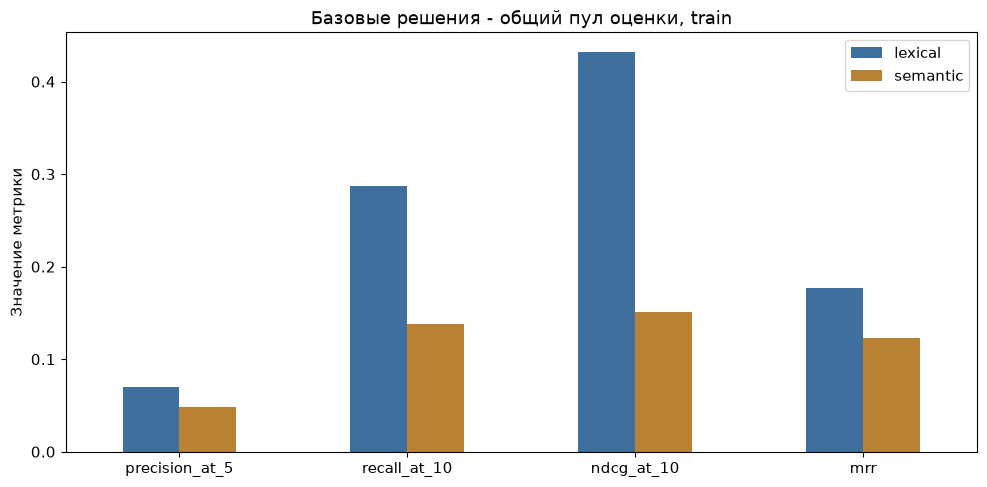

,ndcg_at_10,recall_at_10,mrr
full_catalog,0.0775,0.0543,0.0529
assessed_pool,0.4550,0.3190,0.2005


Запрос: лонгсливы love2wait


,imt_id,imt_name,subj_name,score,assessed_for_query,relevance
0,100827,Лонгсливы,Лонгсливы,0.810145,False,NaN
1,101105,Лонгсливы,Лонгсливы,0.810145,False,NaN
2,101113,Лонгсливы,Лонгсливы,0.810145,False,NaN
3,1000718,Лонгсливы,Лонгсливы,0.810145,True,1.0
4,1000720,Лонгсливы,Лонгсливы,0.810145,False,NaN
5,1001762,Лонгсливы,Лонгсливы,0.810145,False,NaN
6,1001831,Лонгсливы,Лонгсливы,0.810145,False,NaN
7,1002242,Лонгсливы,Лонгсливы,0.810145,False,NaN
8,1002667,Лонгсливы,Лонгсливы,0.810145,False,NaN
9,1002674,Лонгсливы,Лонгсливы,0.810145,False,NaN


In [ ]:
RELEVANCE_THRESHOLD = 2   # Ваше решение, его нужно обосновать

# Ваш код для работы с метриками
KS = [1, 3, 5, 10]

def ranking_metrics(retrieved_ids, relevance_map, ks=KS, threshold=RELEVANCE_THRESHOLD):
    grades = np.array([relevance_map.get(int(item_id), 0) for item_id in retrieved_ids], dtype=float)
    relevant = grades >= threshold
    total_relevant = sum(value >= threshold for value in relevance_map.values())
    positive_ranks = np.flatnonzero(relevant)
    result = {'mrr': 1 / (positive_ranks[0] + 1) if len(positive_ranks) else 0.0}
    for k in ks:
        gains = 2 ** grades[:k] - 1
        discounts = np.log2(np.arange(2, len(gains) + 2))
        ideal = np.array(sorted(relevance_map.values(), reverse=True)[:k], dtype=float)
        ideal_dcg = ((2 ** ideal - 1) / np.log2(np.arange(2, len(ideal) + 2))).sum()
        hits = int(relevant[:k].sum())
        result['precision_at_' + str(k)] = hits / k
        result['recall_at_' + str(k)] = hits / total_relevant if total_relevant else 0.0
        result['hit_rate_at_' + str(k)] = float(hits > 0)
        result['ndcg_at_' + str(k)] = float((gains / discounts).sum() / ideal_dcg) if ideal_dcg else 0.0
    return result

def evaluate(search_function, queries, catalog_size=len(df_products)):
    rows = []
    for query_id, group in queries.groupby('query_id', sort=True):
        relevance_map = dict(zip(group['item_id'], group['relevance']))
        retrieved = search_function(group['query_text'].iloc[0], catalog_size)['imt_id'].tolist()
        rows.append({'query_id': query_id, **ranking_metrics(retrieved, relevance_map)})
    return pd.DataFrame(rows).set_index('query_id')

lexical_results = evaluate(search_lexical, queries_train)
semantic_results = evaluate(search_semantic, queries_train)
baseline_summary = pd.DataFrame({
    'lexical': lexical_results.mean(), 'semantic': semantic_results.mean(),
}).T
baseline_summary.to_csv(ARTIFACT_DIR / 'baseline_metrics.csv')
display(baseline_summary.T.round(4))
baseline_summary[['precision_at_5', 'recall_at_10', 'ndcg_at_10', 'mrr']].T.plot.bar(
    color=['#3E6F9E', '#B88133'], figsize=(10, 5)
)
plt.title('Базовые решения - общий пул оценки, train')
plt.ylabel('Значение метрики')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

diagnostic_ids = queries_train['query_id'].drop_duplicates().sample(100, random_state=SEED)
diagnostic_queries = queries_train.loc[queries_train['query_id'].isin(diagnostic_ids)]
full_results = evaluate(search_lexical_full, diagnostic_queries, len(df_products_full))
pool_results = lexical_results.loc[sorted(diagnostic_ids)]
display(pd.DataFrame({
    'full_catalog': full_results.mean(), 'assessed_pool': pool_results.mean(),
}).T[['ndcg_at_10', 'recall_at_10', 'mrr']].round(4))
first_query = diagnostic_queries.iloc[0]
judgments = queries_train.loc[queries_train['query_id'].eq(first_query['query_id'])].set_index('item_id')['relevance']
full_top = search_lexical_full(first_query['query_text'], 10)
full_top['assessed_for_query'] = full_top['imt_id'].isin(judgments.index)
full_top['relevance'] = full_top['imt_id'].map(judgments)
print('Запрос:', first_query['query_text'])
display(full_top)

Порог 2 отделяет подходящие товары от слабого соответствия с оценкой 1. NDCG использует всю шкалу 0-3, MRR рассчитан по полному ранжированию каталога. Неразмеченные товары принимаются за нерелевантные, поэтому оценка полного каталога может занижать качество. Сравнение моделей ведём на одном общем пуле асессоров и одинаковых train-запросах. Значения при K=5 и K=10 показаны во второй QA-сессии; дополнительно посчитаны K=1 и K=3 из ТЗ. Оценка качества проведена только на train.

На 700 train-запросах сравнили два базовых подхода на общем пуле из 4 256 карточек.

| Метод | NDCG@10 | Recall@10 | Precision@5 | MRR |
|---|---:|---:|---:|---:|
| TF-IDF | 0.4315 | 0.2869 | 0.0697 | 0.1769 |
| Семантический поиск | 0.1512 | 0.1378 | 0.0480 | 0.1233 |

TF-IDF лучше по всем показанным метрикам. В ручных примерах для «топы cop copine» лексический поиск возвращает топы, а семантический - пуловеры, кофты и пиджаки. Для «худи mego as» у семантики худи появляется только на пятом месте. Для «бриджи зуавы» лексика возвращает бриджи, а семантика смешивает обувь и одежду. Бренды исключены из базового текста по QA, поэтому брендовые запросы требуют отдельной обработки.

Модель поддерживает русский язык и возвращает векторы из 384 признаков. Лимит 128 токенов превышают 28.05% карточек; длинные описания обрезаются. При поиске по полному каталогу неоценённые товары получают 0: на одинаковых 100 запросах NDCG@10 лексики равен 0.0775 для полного каталога и 0.4550 для пула оценки. Это ограничение разметки, а не доказательство, что большой каталог хуже.

Для текущего базового решения предпочтителен TF-IDF. На следующем этапе можно проверить другой шаблон текста, нормализацию слов и гибридный поиск. Финальная оценка на test относится к неделе 3.

---

## Неделя 3 — эксперименты, дообучение и MLflow

**Цель:** проверить гипотезы о том, как можно улучшить систему поиска, зафиксировать эксперименты, дать рекомендации бизнесу.

**Главное правило:** «один эксперимент — одна гипотеза — одно изменение». Если поменять сразу модель, шаблон текста и параметры векторизации, прирост будет невозможно объяснить и повторить.

### 1. Эксперименты по улучшению

Проведите минимум три эксперимента. Оформляйте каждый по схеме:

- **Гипотеза** — ваше предположение и его обоснование. Причины «хочу попробовать другую модель» недостаточно, нужны объяснения такого типа: «Модель с большим окном улучшит поиск товаров с длинными описаниями, потому что в EDA я видел, что X% описаний обрезаются по лимиту токенов».
- **Что меняется** — ровно один компонент относительно baseline.
- **Результат** — метрики на тех же данных, с тем же порогом и теми же K.
- **Вывод** — принимаем или отклоняем гипотезу. Что это говорит о данных?

Придумывайте гипотезы, опираясь на ошибки, которые обнаружили на неделе 2. Если выбранная модель путает смежные категории, попробуйте проверить, решит ли проблему добавление данных из `subj_name` в общий текст карточки. Другой пример: если лексический поиск обходит семантический на точных названиях, а семантический выигрывает у лексического, когда дело доходит до неточных формулировок, — это повод попробовать реализовать гибридный поиск.

Направления для разработки гипотез:

- изменить шаблон `product_text`;
- попробовать другую модель эмбеддингов;
- дообучить модели;
- реализовать гибридный поиск с помощью взвешенной суммы скоров или реранкинга семантикой поверх лексического отбора;
- ввести лемматизацию и стоп-слова для TF-IDF;
- изменить параметры векторизации.

In [ ]:
# Эксперимент 1
# Гипотеза:
# Что меняем:


# Ваш код

...

### 2. Финальный тест

Выборка `test` нужна для финальной проверки модели, когда конфигурация окончательно выбрана по результатам валидации. Каждый повторный прогон с подстройкой превращает `test` в ещё одну валидацию и обесценивает финальные показатели.

In [ ]:
RUN_FINAL_TEST_EVAL = False   # Переведите в True, когда конфигурация финальная

# Ваш код


### 3. Трекинг экспериментов в MLflow

Каждая конфигурация — отдельный run с осмысленным именем (`semantic_bge_m3`, а не `run_7`).

Что логировать:
- Все параметры, известные до запуска, — метод, модель, шаблон текста, порог, размер каталога, сид.
- Метрики — все посчитанные значения.
- Артефакты — таблица метрик по запросам, сводная таблица, графики, копия данных, на которых проводилась проверка.

In [ ]:
# Ваш код: подключение к MLflow из .env и логирование прогонов

### 4. Финальные выводы

**4.1. Сводная таблица.** Все подходы на одних данных, с одинаковыми порогом и K. Укажите лучшую конфигурацию и метрики, по которым был сделан вывод.

**4.2. Качественный анализ.** Числа показывают не всю картину. Возьмите запросы, где лучший подход всё ещё ошибается, и опишите характер ошибок.

**4.3. Ограничения оценки.** Перечислите ограничения модели и данных, на которых проводились эксперименты. Например:

- разметка синтетическая и пулированная;
- каталог оценки меньше реального;
- запросы сгенерированы, а не собраны от пользователей.

Этот раздел не ослабляет работу, а усиливает её: специалист, понимающий границы своего решения, вызывает больше доверия.

**4.4. Рекомендация бизнесу.** Скажите заказчику, внедрять ли ему векторный поиск или нет, в каком виде его лучше реализовывать, в каких сценариях он будет помогать, а где может ошибаться.

**4.5. Дальнейшие шаги.** Перечислите возможные действия, которые могли бы улучшить результат:

- использовать реальные логи запросов вместо синтетических;
- перейти на ANN-индекс при росте каталога;
- применить фильтры по атрибутам поверх векторного поиска.

Все возможные шаги обоснуйте.


*Ваши выводы:*
